In [1]:
"""
Created By    : Jared W. Marquis
Creation Date : 01 August 2022
Course        : ATSC 528 - Atmospheric Data Analysis
Assignment    : #03 - Statistical Objective Analysis

Purpose:
Script to take sparse upper air observations and analyze them on a
polar stereographic map projection using statistical objective analysis.
[PUT MORE INFORMATION HERE - I.E., WHAT SPECIFIC THING IS BEING DONE]

"""
__author__    = "Jared W. Marquis"
__contact__   = "jared.marquis@und.edu"

In [1]:
### Import Required Modules (shouldn't need to change) ###
import numpy as np                 #numpy for math
import matplotlib.pyplot as plt    #matplotlib for plotting
import cartopy.crs as ccrs         #cartopy for plotting on map
import cartopy.feature as cfeature #cartopy basic shapefiles

import pandas as pd # WOOOO PANDAAAAAS

In [2]:
### Read in observations ###

# SID LAT LON HGT DIR SPD
# 0   1   2   3   4   5

# I think you'll have to change this if you're grading on a non-UNIX machine... sorry
observation_file = r"../RAOBs_201903131200.txt"


# This reads the data as comma-separated values, creating a pandas dataframe that is subsequently converted into a numpy array for easy manipulation later.
# Oh and it has no headers, which also makes things easier later.
observations = pd.read_csv(observation_file, header=None).to_numpy()

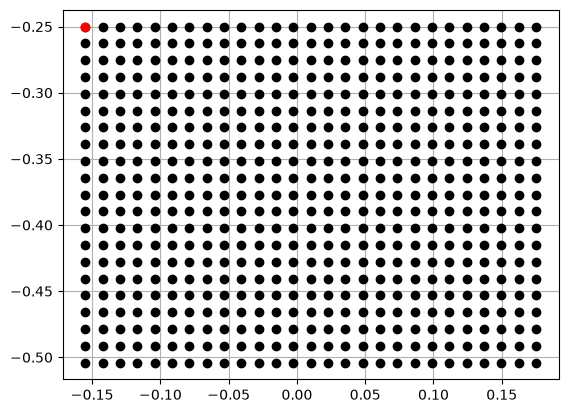

In [3]:
### Set up analysis map with a 21x27 rectangular grid of points ###
''' We have a polar stereographic projection with a standard latitude of 60degN and a standard latitude of 100degW. Map scale is 1/15,000,000. 
    We need our origin at 90degN latitude and 0deg longitude, with grid points every 1.27cm extending to x = +- 25cm and y = +- 15.5cm.
    The first array member (0,0) is supposed to be at x = 25cm, y = -15.5cm.
'''

#np array element format: array[col][row], both starting at zero

# Init lists of x- & y-values
x = []
y = []

# x- & y-values at (0,0)
x0 = .25
y0 = -.155

# Populating the x & y lists with all the values on the grid
# You will note that all cm values have been converted to m
for i in range(27):
    diff = i * .0127
    if(i < 21):
        x.append(x0 + diff)
    y.append(y0 + diff)

x = np.array(x)
y = np.array(y)

# Use the x- & y-values to populate two new numpy arrays with the values necessary to actually graph all gridpoints
gridx, gridy = np.meshgrid(x,y)

testx = [-.25]
testy = [-.155]

# Plot the grid of values, to ensure that we made it correctly
fig, ax = plt.subplots()
ax.plot(gridy, -gridx, marker='o', color='k', linestyle='none')
ax.plot(testy, testx, marker='o', color='r', linestyle='none')
ax.grid()
plt.show()


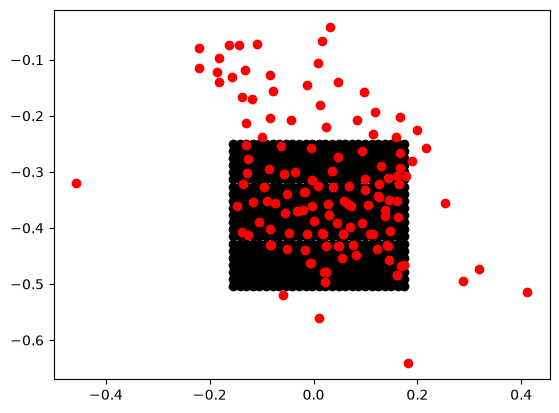

In [4]:
### convert obs lat/long to x,y ###

# Conversion factor we need cuz numpy trig fcns are in radians
degToRad = np.pi / 180

# Defining our standard latitude & longitude
standardLat = 60 * degToRad
standardLong = -100 * degToRad

# Earth's mean radius, in meters
rho = 6.371e6

# Map scale
m = 1 / 15e6

# Helper function for calculating scale factor
def __scaleFactor__(lat: float) -> float:
    sigmaNumerator = 1 + np.sin(standardLat)
    sigmaDenominator = 1 + np.sin(lat)

    return (sigmaNumerator / sigmaDenominator)

# Defining a function to convert from lat/long to x/y
def getCartesian(latDeg: float, longDeg: float) -> (float,float):
    lat = latDeg * degToRad
    long = (longDeg * degToRad) - standardLong
    sigma = __scaleFactor__(lat)
    r = m * rho * sigma * np.cos(lat)
    x = r * np.cos(long)
    y = r * np.sin(long)

    return x,y



# Initializing lists for the x- & y-values we will calculate from the observation lat/long
obsx = []
obsy = []

for i in range(observations.shape[0]):
    tempx, tempy = getCartesian(observations[i][1], observations[i][2])
    obsx.append(tempx)
    obsy.append(tempy)

# Turning lists into np arrays because they're much nicer to work with
obsx = np.array(obsx, dtype=np.double)
obsy = np.array(obsy, dtype=np.double)

# Check points with a graph
fig, ax = plt.subplots()
ax.plot(gridy, -gridx, marker='o', color='k', linestyle='none')
ax.plot(obsy, -obsx, marker='o', color='r', linestyle='none')
plt.show()

# The points do appear to be in the correct locations

In [44]:
### GENERATE BACKGROUND FIELD ###


roi = .127775892 # meters


# functions for bilinear interpolation, because we are generating a background field, so we need values at observation points
def toIndexSpace(x: np.ndarray or float, x0: float) -> np.ndarray or float:
    delta = .0127
    return ( (x - x0) / delta )

def bilinearInterpolate(xo: float, yo: float, xGrid: np.ndarray, yGrid: np.ndarray, analysisArr: np.ndarray) -> float:
    '''Take an observation point and calculate the analysis value there with bilinear interpolation using the nearest four analysis points. See cell below for equation.'''


    # Defining the values at the origin of index space
    x0 = .25
    y0 = -.155

    # Transform the grid of analysis points into index space
    xIndices = toIndexSpace(xGrid, x0)
    yIndices = toIndexSpace(yGrid, y0)

    # Transform the observation point into index space
    xoIndex = toIndexSpace(xo, x0)
    yoIndex = toIndexSpace(yo, y0)

    # Calculate the x- and y-indices of the four points surrounding the observation point
    x1 = int(np.floor(xoIndex))
    x2 = x1 + 1
    y1 = int(np.floor(yoIndex))
    y2 = y1 + 1

    # Use the indices to find the analysis values at the four analysis points
    tlVal = analysisArr[x1][y1]
    trVal = analysisArr[x2][y1]
    blVal = analysisArr[x1][y2]
    brVal = analysisArr[x2][y2]

    # Construct the component matrices of the matrix-form bilinear interpolation equation (see the cell below)
    matX = np.array([x2 - xoIndex, xoIndex - x1])
    matQ = np.array([[tlVal, blVal], [trVal, brVal]])
    matY = np.array([[y2 - yoIndex], [yoIndex - y1]])

    # Calculate the analysis value at the observation point with some matrix multiplications (and an index because it returns a 1x1 numpy array and I want a float !!!)
    output = (matX @ matQ @ matY)[0]
    
    return output

def isOutsideGrid(x: float, y: float) -> bool:
    '''Determine whether a point is inside or outside the bounds of the analysis grid. Returns True if the point is OUTSIDE the grid.'''
    return (x < .25) or (x > .504) or (y < -.155) or (y > .1752)

def backgroundFromAnalysis(analysis: np.ndarray, gridAnalysis: np.ndarray, prevBG: np.ndarray, roi: float) -> np.ndarray:
    '''Take a set of analysis values and use them to generate background values at each observation point'''
    background = []
    
    out = 0
    for i in range(len(obsx)):

        if(isOutsideGrid(obsx[i],obsy[i])):
            # If the observation point is outside the analysis grid, we interpolate with the Cressman function
            bgVal = analyze(obsx[i], obsy[i], gridx.flatten(), gridy.flatten(), analysis, roi)
            if(np.isinf(bgVal)):
                bgVal = np.nan

        else:
            bgVal = bilinearInterpolate(obsx[i], obsy[i], x, y, gridAnalysis)
            out += 1

        background.append(bgVal)
    background = np.array(background)
    
    print(out)


    return background



# Defining the weight function used for the background
def weightFunc(dist: float, roi) -> float:
    w = 0

    if (dist <= roi):
        Kd = .00108844524 # sq meters
        numerator = -(dist ** 2)
        exponent = numerator / Kd
        w = np.exp(exponent)
        
    return w

def analyze(xa: float, ya: float, xArr: np.ndarray, yArr: np.ndarray, obsArr: np.ndarray, roi: float) -> float:
    '''
    Do a single-pass Barnes analysis at point (xa, ya) based on input observations.
    '''
    obsArr = np.asarray(obsArr, dtype=float)
    # Make arrays of the (signed) x- & y-distance between the analysis point and the observation points in the RoI
    xDist = xa - xArr
    yDist = ya - yArr
    
    # Initialize an empty np array that will be filled with the weights
    weights = np.ndarray((obsArr.shape[0],))

    # Populate the weights array using the weight function
    for i in range(obsArr.shape[0]):
        dist = np.hypot(xDist[i], yDist[i])
        weights[i] = weightFunc(dist, roi)

    # Initializing a couple variables that get their real value in a conditional later
    num = np.nansum(weights * obsArr)
    # Define the denominator of the fraction in the analysis function
    denom = np.nansum(weights)
    if (denom > 0):
        return num / denom
    else:
        return np.nan
    

bgAnalysis = []
bgGrid = np.ndarray((len(x),len(y)))

for i in range(len(x)):
    for j in range(len(y)):
        currVal = analyze(x[i], y[j], obsx, obsy, observations[:,3], roi)
        bgAnalysis.append(currVal)
        bgGrid[i][j] = currVal

bgAnalysis = np.array(bgAnalysis)

bgObservations = backgroundFromAnalysis(bgAnalysis, bgGrid, observations[:,3], roi)

print(bgObservations)

92
[5477.06391914 5789.87755319 5363.01714534 5703.16339265 5607.65714156
 5578.89398265           nan 5521.11234511 5684.93811529 5788.25076254
           nan 5452.55561249 5674.56245318 5378.02029586           nan
 5786.89926191 5548.67902272 5632.42636466 5704.29560705 5524.56775207
 5520.8579849  5624.74366013 5785.90113249 5447.07467684 5782.0868299
 5496.41659964 5479.75477786 5534.34841386 5440.16303219 5706.3881607
           nan 5485.38470205 5635.99784177 5532.19583985 5432.01738516
 5444.91074004 5640.35599308 5756.29939946           nan 5507.7264236
 5809.63599109 5768.11117784 5426.5042692  5802.37227427           nan
 5670.29968021 5749.24658376 5524.40817656           nan 5788.30524788
 5808.91231395 5777.45677321 5553.26818802 5469.01546059 5685.76979591
 5538.31245058 5468.15486839 5681.5061645  5672.46856956 5660.97153406
 5524.49147373 5877.20532954           nan 5813.36674183 5499.74009842
 5634.59170551 5693.89233899 5449.24108271 5446.1035338  5632.71896119
 5764.

The analysis equation we use for generating the background *and* for SOA is given by
$$
f_{A}(\vec{r}_{i}) = f_{B}(\vec{r}_{i}) + \sum_{k=1}^{K} w_{ik} [f_{O}(\vec{r}_{k}) - f_{B}(\vec{r}_{k})]
.$$
The difference is that we use different weight functions for each. The background uses
$$
w(d_{ik}) = \exp\left( \frac{-d^{2}_{ik}}{K_{d}} \right),
$$
while the actual analysis uses
$$
\sum_{l=1}^{K}w_{ik}\rho_{kl} = \rho_{ik.}
$$

I will not go into the details of what the constants are and how these weights are found, as those details are in the assignment paper.

Schlatter (1975) provides a formula for the great-circle distance $s$ between two points ${}(\lambda_{i},\varphi_{i}){}$ and ${}(\lambda_{j}, \varphi_{j}){}$:
$$
s = a \left[ (\lambda_{i} - \lambda_{j})^{2} \cos ^{2}\left( \frac{\phi_{i} + \phi_{j}}{2} \right) + (\phi_{i} - \phi_{j})^{2} \right]^{1/2}, 
$$
where $a$ is the Earth's radius in thousands of kms, and LAT AND LONG ARE IN RADIANS??? I mean, it makes sense for the cosine, but man that is weird.

We have the observation point lat/long, as those were provided in the dataset. However, we do not have analysis point lat/long, so those must be calculated.

In [6]:
### ANALYSIS POINT LAT/LONG ###

def getLatLong(x: float, y: float) -> (float, float):

    x = x / m
    y = y / m

    latTanArg = np.sqrt((x ** 2) + (y ** 2)) / (rho * (1 + np.sin(standardLat)))
    lat = (np.pi / 2) - (2 * np.atan(latTanArg))

    long = np.atan2(y, x)

    lat = np.rad2deg(lat)
    long = np.rad2deg(long) + np.rad2deg(standardLong)

    return lat, long

analysisLat = []
analysisLong = []

for i in range( len( gridx.flatten() )):
    tempLat, tempLong = getLatLong(gridx.flatten()[i], gridy.flatten()[i])
    analysisLat.append(tempLat)
    analysisLong.append(tempLong)

analysisLat = np.array(analysisLat)
analysisLong = np.array(analysisLong)

print(analysisLat)

[49.27626501 47.90148837 46.52223442 45.14090754 43.75964131 42.38033071
 41.00465995 39.63412665 38.27006269 36.91365236 35.56594803 34.2278839
 32.90028799 31.5838926  30.27934365 28.98720878 27.70798468 26.44210353
 25.1899388  23.95181044 22.72798959 50.10314636 48.69106774 47.27660805
 45.8620428  44.44938084 43.0403981  41.63666637 40.23957774 38.85036565
 37.47012277 36.0998165  34.74030232 33.39233537 32.05658058 30.73362148
 29.42396804 28.1280635  26.84629054 25.57897674 24.32639944 23.08879019
 50.88000027 49.43166353 47.98313228 46.53652567 45.09370583 43.6563122
 42.22579026 40.80341573 39.39031508 37.98748283 36.59579637 35.2160287
 33.84885934 32.49488382 31.15462199 29.82852529 28.5169831  27.22032851
 25.93884333 24.67276264 23.42227889 51.60238901 50.11922533 48.63810807
 47.16097518 45.6895229  44.22523946 42.76943288 41.32325415 39.88771656
 38.46371201 37.0520248  35.65334334 34.26827027 32.89733111 31.54098191
 30.19961578 28.8735688  27.56312519 26.26852189 24.98

In [7]:
### CALCULATE COVARIANCES ###



def greatCircleDistance(lat1: float, long1: float, lat2: float, long2: float) -> float:

    # We need the lat/long in radians because we are in crazy town
    lat1 = np.deg2rad(lat1)
    long1 = np.deg2rad(long1)
    lat2 = np.deg2rad(lat2)
    long2 = np.deg2rad(long2)

    # A bunch of sub-calculations so that the calculation of s isn't a giant illegible nightmare
    sqLatDiff = (lat1 - lat2) ** 2
    sqLongDiff = (long1 - long2) ** 2
    cosArg = ((lat1) + (lat2)) / 2
    cosine = np.cos(cosArg) ** 2
    adjEarthRad = rho / 1e6 # Putting Earth's radius in the correct units (thousands of km)
    term1 = sqLongDiff * cosine
    
    # s
    s = adjEarthRad * np.sqrt(term1 + sqLatDiff)
    
    return s

# Calculate a single covariance, given a distance s in thousands of km.
def getErrorCorrelation(s: float) -> float:
    expFactor = -1.24 
    
    exponent = expFactor * (s ** 2)
    out = 0.95 * np.exp(exponent)
    if (s < 1e-8):
        out = 1

    return out

print(greatCircleDistance(47.913, -97.146, 47.924, -97.134))

0.001515182115837718


In [72]:
### DO ANALYSIS ###

N = np.array([2,4,10]) # Number of stations to use for each analysis

def closestPoints(alat: float, along: float) -> (np.ndarray, np.ndarray):
    # Take a point in lat/long and return an array of the observation points in lat/long, sorted by proximity to the input point
    distances = []

    for i in range(len(obsx)):
        dist = greatCircleDistance(alat, along, observations[i,1], observations[i,2])
        distances.append(dist)
    
    distances = np.array(distances)
    fixArr = np.argsort(distances)
    nearLats = np.take_along_axis(observations[:,1], fixArr)
    nearLongs = np.take_along_axis(observations[:,2], fixArr)
    return nearLats, nearLongs

def getMatrices(lata: float, longa: float, nearLats: np.ndarray, nearLongs: np.ndarray):
    # Take an analysis point in lat/long, as well as a list of observation points sorted by proximity, and calculate the covariance matrices needed by the weight function

    analysisMatrix = np.ndarray((len(nearLats),))
    bigMatrix = np.ndarray((len(nearLats),len(nearLats)))
    
    for i in range(len(nearLats)):
        ptDist = greatCircleDistance(lata, longa, nearLats[i], nearLongs[i])
        covar = getErrorCorrelation(ptDist)
        analysisMatrix[i] = covar
        for j in range(len(nearLats)):
            ptDist = greatCircleDistance(nearLats[i], nearLongs[i], nearLats[j], nearLongs[j])
            covar = getErrorCorrelation(ptDist)
            bigMatrix[i][j] = covar

    return analysisMatrix, bigMatrix

def analysisFunc(index: float, jndex: float, n: float, weights: np.ndarray) -> float:
    
    obsIncs = observations[:,3] - bgObservations
    weightTerm = np.nansum(weights * obsIncs[:n])
    anVal = bgGrid[index][jndex] + weightTerm
     
    return anVal

analysis2 = []
analysis4 = []
analysis10 = []
a = [analysis2, analysis4, analysis10]

graphZ2 = np.ndarray((len(x),len(y)))
graphZ4 = np.ndarray((len(x),len(y)))
graphZ10 = np.ndarray((len(x),len(y)))

z = [graphZ2, graphZ4, graphZ10]

for n in range(len(N)):
    for i in range(len(x)):
        for j in range(len(y)):
            
            # Get the observation points, sorted by proximity to the analysis point 
            # Then, truncate the lists to the desired length. This dramatically shrinks the matrix that will need to be inverted, reducing runtime by several orders of magnitude (i tested) 
            nLats, nLongs = closestPoints(analysisLat[i], analysisLong[j])
            nLats = nLats[:N[n]]
            nLongs = nLongs[:N[n]]

            anMat, bigMat = getMatrices( analysisLat[i], analysisLong[j], nLats, nLongs )
            
            # Make sure we don't try to invert a singular matrix, just in case
            if(np.linalg.det(bigMat) != 0):
                invBigMat = np.linalg.inv(bigMat)
            else:
                invBigMat = np.linalg.pinv(bigMat)

            weights = invBigMat @ anMat
            if(n == 2 and i == 12 and j == 15):
                print(anMat)
                print(analysisLat[i], analysisLong[j])
                # print(nLats)
                # print(nLongs)
                # print(greatCircleDistance(analysisLat[i], analysisLong[j], nLats[0], nLongs[0]))
            currVal = analysisFunc(i, j, N[n], weights)
            a[n].append(currVal)
            z[n][i][j] = currVal

    a[n] = np.array(a[n])

print(z[2])

[0.94332452 0.89778444 0.67862929 0.61275936 0.4771521  0.47362106
 0.42925183 0.4220129  0.2755847  0.2147527 ]
32.90028798621293 -119.38558734963141
[[5570.64969444 5448.71016575 5412.99572884 5365.61493172 5354.36952682
  5301.91900623 5254.04344066 5223.65044046 5199.74205043 5216.7520394
  5274.98809724 5225.00918095 5207.31060036 5187.49668634 5250.99155784
  5292.01863055 5319.42391621 5338.77377339 5336.08235319 5335.6543517
  5360.29728525 5379.24622244 5351.22409533 5377.83159345 5359.46837699
  5338.04592982 5320.83787495]
 [5489.71761772 5478.32619274 5407.65335203 5343.17108513 5391.20769275
  5358.5332415  5330.99273856 5306.78768926 5291.38889465 5269.63969922
  5351.11688405 5371.20957822 5321.6220109  5319.59558565 5382.24198496
  5352.22493731 5349.54621141 5341.51933612 5350.62480088 5342.37402891
  5361.98653228 5420.77735063 5382.28386401 5470.1005362  5467.08615194
  5458.25694726 5437.12837564]
 [5518.71863462 5417.16662747 5419.49273031 5516.00907758 5446.431683

In [75]:
### DEBUG CELL ###

lol = 6
lul = 7

test, nest = closestPoints(analysisLat[lol], analysisLong[lul])

test = test[:N[1]]
nest = nest[:N[1]]

SMALL, BIG = getMatrices(analysisLat[lol], analysisLong[lul], test, nest)

INVBIG = np.linalg.inv(BIG)

WTS = INVBIG @ SMALL

salt = analysisFunc(lol, lul, 4, WTS)

print(SMALL)
print(BIG)
print(salt)
print(test)
print(nest)

[0.89862394 0.76528989 0.73582639 0.64037183]
[[1.         0.68071344 0.85958195 0.70015922]
 [0.68071344 1.         0.4276635  0.7766081 ]
 [0.85958195 0.4276635  1.         0.50474241]
 [0.70015922 0.7766081  0.50474241 1.        ]]
5386.775883620942
[42.37 37.73 44.92 39.57]
[-122.8 -122.2 -123.0 -118.2]


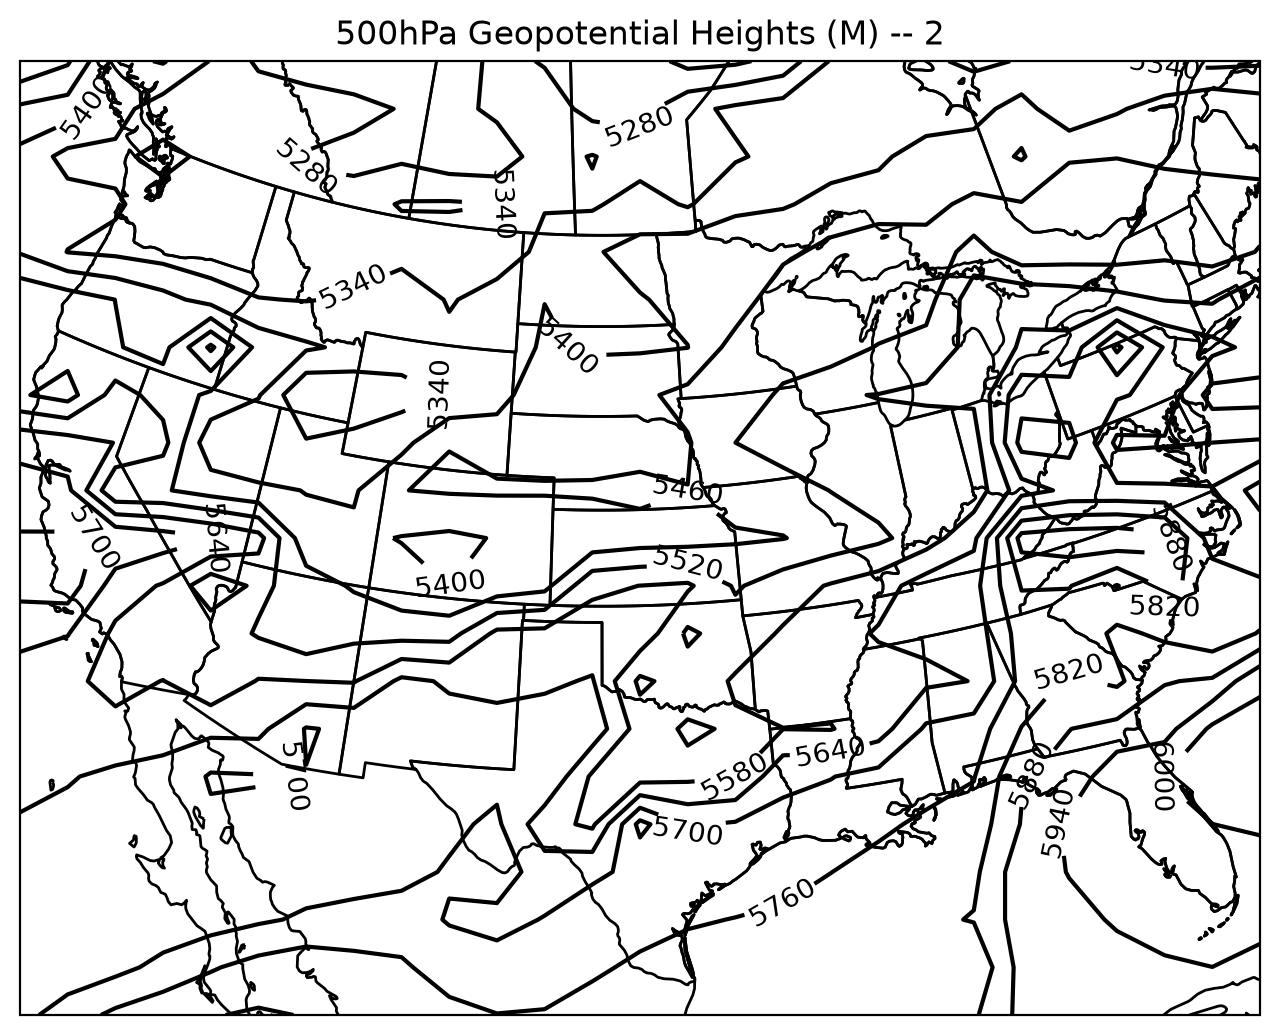

In [74]:
### Plot 500mb analyses over a map ###

# CartoPy throws a fit if I don't include this
import os
os.environ["PROJ_IGNORE_CELESTIAL_BODY"] = "YES"

globe = ccrs.Globe(ellipse=None, semimajor_axis=rho/100, semiminor_axis=rho/100)
proj = ccrs.Stereographic(central_longitude=-100,central_latitude=90,true_scale_latitude=60,globe=globe)
fig = plt.figure(figsize=(8,8),dpi=200)
ax1 = fig.add_subplot(111,projection=proj)
ax1.add_feature(cfeature.STATES)
ax1.add_feature(cfeature.COASTLINE)
# plot analysis (MAY NEED TO CHANGE VARIABLE NAMES/INDICES) #
cs1 = ax1.contour(gridy/100/m,-gridx/100/m,graphZ4.T,colors='k',levels=np.arange(0,8000,60),transform=proj)
plt.clabel(cs1,levels=np.arange(0,8000,60))

ax1.set(title='500hPa Geopotential Heights (M) -- 2')

plt.show()

In [ ]:
### In a separte text file (or below), answer the following questions ###
'''
1 - Describe the general features that you see in your contoured analyses.
    

2 - Describe the differences that you see in your contoured analyses.  
    Does one analysis seem to be smoother than the other?  If so, what would cause this?
    

3 - What happens as you increase the number of points considered for the analysis?  Is this 
    desirable?  Why or why not?
    
'''